# Stage 6 — Who to Contact First

Goal: rank current customers so a retention team knows who to contact first.

Questions:
- Should we rank by **risk alone**, or by **risk × monthly bill**?
- Who ends up at the top of the list?

**This is a ranking system, not proof that contacting customers prevents churn.** It says who looks most like past churners and how much they pay. Whether an offer changes their decision can only be shown by a test.

**Assumptions:**
- Value = monthly bill. There's no profit, cost or lifetime data, so `monthly_bill_at_risk` (score × bill) is a ranking number, not a dollar loss.
- The data is a snapshot, so scores mean "looks like past churners", not "will leave next month".

## Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from features import CATEGORICAL_FEATURES, ID_COLUMN, NUMERIC_FEATURES, load_modelling_data
from modeling import CV
from train_model import build_model

FIGURES = ROOT / "reports" / "figures"
EXPORT = ROOT / "dashboard" / "data"
EXPORT.mkdir(parents=True, exist_ok=True)

# Same style as the earlier charts.
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "grid.color": "#e5e5e2", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

RISK_CUTOFF = 0.32   # chosen in Stage 5 on training data; kept as is, not re-tuned here

data = load_modelling_data()
X = data[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = data["y"]

7,032 customers for modelling (11 with tenure = 0 excluded)


## Score every customer fairly

Each customer is scored by a model that didn't train on them (5-fold out-of-fold scores). That way no one gets an unfairly confident score.

In [2]:
data["churn_probability"] = cross_val_predict(
    build_model(), X, y, cv=CV, method="predict_proba")[:, 1]
data["monthly_bill_at_risk"] = data["churn_probability"] * data["MonthlyCharges"]

print(f"Scored {len(data):,} customers")
print(f"Average score {data['churn_probability'].mean():.3f} vs actual churn {y.mean():.3f}")

Scored 7,032 customers
Average score 0.266 vs actual churn 0.266


## Which ranking works best?

We can only check rankings where outcomes are known, so this test uses **all customers, including those who left**: if we had used each ranking, how many churners would the top of the list have included?

| Ranking | Sort by |
|---|---|
| **Risk only** | churn score |
| **Risk × bill** | churn score × monthly charge |
| **Bill only** | monthly charge |
| **Simple rule** | month-to-month + fiber first, then highest bill (no model) |

Two measures, because they pull in different directions:
- **Churners caught:** share of all churners in the contacted group
- **Churned billing reached:** share of churners' monthly billing in the contacted group

In [3]:
churned_billing = (data["MonthlyCharges"] * y).sum()
# Simple rule: month-to-month fiber customers first, highest bill first within each group.
data["simple_rule"] = (
    1000 * (data["Contract"].eq("Month-to-month") & data["InternetService"].eq("Fiber optic"))
    + data["MonthlyCharges"])

POLICIES = {"Risk only": "churn_probability", "Risk × bill": "monthly_bill_at_risk",
            "Bill only": "MonthlyCharges", "Simple rule": "simple_rule"}

def reached(column):
    order = data.sort_values(column, ascending=False, kind="stable")
    churners = order["y"].cumsum().to_numpy() / y.sum()
    billing = (order["MonthlyCharges"] * order["y"]).cumsum().to_numpy() / churned_billing
    return churners, billing

curves = {name: reached(column) for name, column in POLICIES.items()}

rows = []
for b in [0.10, 0.20, 0.30]:
    i = int(np.ceil(len(data) * b)) - 1
    for name, (churners, billing) in curves.items():
        rows.append({"contact": f"top {b:.0%}", "ranking": name,
                     "churners caught %": 100 * churners[i],
                     "churned billing reached %": 100 * billing[i]})
comparison = pd.DataFrame(rows).pivot(index="ranking", columns="contact").round(1)
comparison.loc[list(POLICIES)]

churners caught %                 churned billing reached %  \
contact               top 10% top 20% top 30%                   top 10%   
ranking                                                                   
Risk only                28.5    50.8    66.3                      32.4   
Risk × bill              27.3    48.8    63.3                      33.5   
Bill only                 9.3    24.7    37.6                      13.4   
Simple rule              20.3    39.5    61.6                      27.2   

                             
contact     top 20% top 30%  
ranking                      
Risk only      55.9    70.6  
Risk × bill    57.1    72.8  
Bill only      33.7    49.2  
Simple rule    49.5    71.7

In [4]:
# Is the risk × bill vs risk-only gap real? Resample customers and recompute the top-20% gap.
# This resamples customers but does not retrain the model, so the true
# uncertainty is somewhat wider than this range.
rng = np.random.default_rng(42)
k = int(np.ceil(len(data) * 0.20))
gaps = []
for _ in range(1000):
    sample = data.iloc[rng.integers(0, len(data), len(data))]
    total = (sample["MonthlyCharges"] * sample["y"]).sum()
    share_reached = {}
    for name, column in [("risk", "churn_probability"), ("bar", "monthly_bill_at_risk")]:
        top = sample.nlargest(k, column)
        share_reached[name] = (top["MonthlyCharges"] * top["y"]).sum() / total
    gaps.append(100 * (share_reached["bar"] - share_reached["risk"]))

print(f"Top 20% churned-billing gap (risk × bill − risk only): {np.mean(gaps):.1f} pts, "
      f"likely range {np.percentile(gaps, 2.5):.1f} to {np.percentile(gaps, 97.5):.1f}")

Top 20% churned-billing gap (risk × bill − risk only): 1.3 pts, likely range 0.2 to 2.4


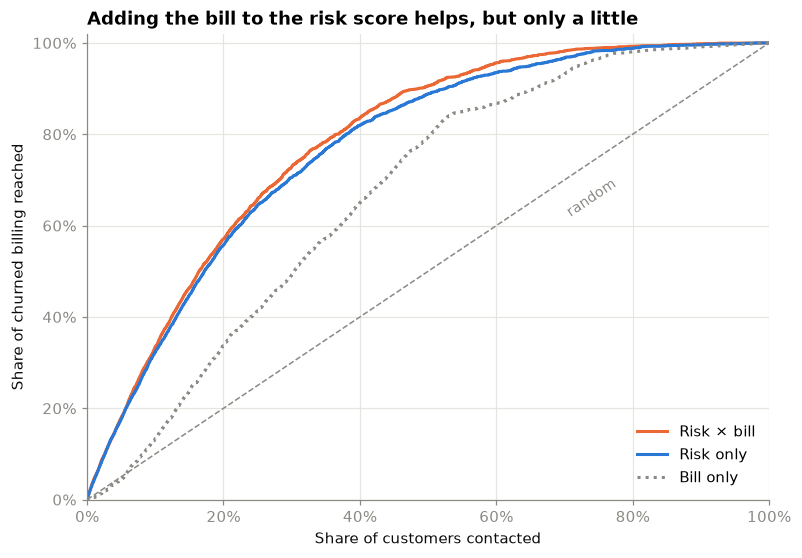

In [5]:
share = np.arange(1, len(data) + 1) / len(data)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
ax.text(0.70, 0.62, "random", color=MUTED, fontsize=9, rotation=34)
styles = {"Risk × bill": (ORANGE, "-"), "Risk only": (BLUE, "-"), "Bill only": (MUTED, ":")}
for name, (color, style) in styles.items():
    ax.plot(share, curves[name][1], color=color, linestyle=style, linewidth=2, label=name)
ax.legend(frameon=False, loc="lower right")

ax.set_title("Adding the bill to the risk score helps, but only a little")
ax.set_xlabel("Share of customers contacted")
ax.set_ylabel("Share of churned billing reached")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(); ax.set_axisbelow(True)
save(fig, "11_ranking_comparison")
plt.show()

**Risk × bill vs risk only is a trade-off, not a free win.** At the top 20%:

| | Churners caught | Churned billing reached |
|---|---|---|
| Risk only | **50.8%** | 55.9% |
| Risk × bill | 48.8% | **57.1%** |

Risk × bill reaches **1.3 points more billing** (likely range 0.2–2.4) but catches **2 points fewer churners**. Which is better depends on the goal: protecting revenue or keeping the most customers. Both effects are small.

**Why so small?** Risky customers here already pay more (most are on fiber, the expensive plan), so ranking by risk already picks high payers.

**The model beats the simple rule on small lists.** At the top 10–20%, the rule (month-to-month fiber, highest bill first) reaches 6–8 points less billing and catches 8–11 points fewer churners. At the top 30% they nearly tie, because month-to-month fiber is about 30% of customers, so both pick almost the same people.

**Bill only is much worse.** Many high payers are on long contracts and rarely leave.

## The priority list

Now the real output: **current customers only** (the ones who haven't left), ranked by monthly bill at risk.

Each customer goes into one of four buckets. The two cutoffs are choices, not model results:
- **Score 0.32:** the Stage 5 threshold, kept as is.
- **Median bill ($64.45):** a simple business rule that splits customers in half. A team could just as well use $50 or $80.

| | Bill above median | Bill below median |
|---|---|---|
| **Score ≥ 0.32** | **Contact first** | Low-cost outreach |
| **Score < 0.32** | Monitor | Leave alone |

In [6]:
current = data[data["y"].eq(0)].copy()
value_cutoff = current["MonthlyCharges"].median()   # business rule, not a model result

high_risk = current["churn_probability"] >= RISK_CUTOFF
high_value = current["MonthlyCharges"] >= value_cutoff
current["bucket"] = np.where(
    high_risk, np.where(high_value, "Contact first", "Low-cost outreach"),
    np.where(high_value, "Monitor", "Leave alone"))

current = current.sort_values("monthly_bill_at_risk", ascending=False)
current["priority_rank"] = np.arange(1, len(current) + 1)

print(f"{len(current):,} current customers, median monthly charge ${value_cutoff:.2f}")
BUCKET_ORDER = ["Contact first", "Low-cost outreach", "Monitor", "Leave alone"]
buckets = current.groupby("bucket").agg(
    customers=("bucket", "size"),
    avg_score=("churn_probability", "mean"),
    avg_monthly_charge=("MonthlyCharges", "mean"),
    monthly_bill_at_risk=("monthly_bill_at_risk", "sum"),
).reindex(BUCKET_ORDER)
buckets["share_of_bill_at_risk_%"] = 100 * buckets["monthly_bill_at_risk"] / current["monthly_bill_at_risk"].sum()
buckets.round(2)

5,163 current customers, median monthly charge $64.45


,customers,avg_score,avg_monthly_charge,monthly_bill_at_risk,share_of_bill_at_risk_%
bucket,,,,,
Contact first,830,0.54,86.42,38515.38,56.77
Low-cost outreach,277,0.42,44.82,5242.84,7.73
Monitor,1755,0.10,89.56,16438.02,24.23
Leave alone,2301,0.09,32.68,7647.71,11.27


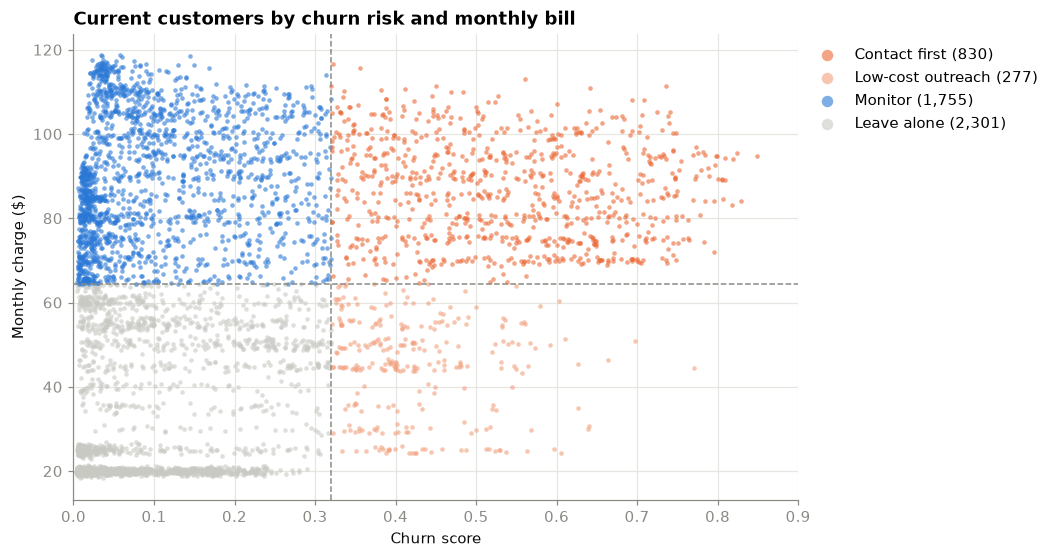

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
colors = {"Contact first": ORANGE, "Low-cost outreach": "#f2a07e",
          "Monitor": BLUE, "Leave alone": "#c9c9c4"}
for bucket in BUCKET_ORDER[::-1]:
    rows = current[current["bucket"].eq(bucket)]
    ax.scatter(rows["churn_probability"], rows["MonthlyCharges"], s=9, alpha=0.6,
               color=colors[bucket], label=f"{bucket} ({len(rows):,})", linewidths=0)

ax.axvline(RISK_CUTOFF, color=MUTED, linewidth=1, linestyle="--")
ax.axhline(value_cutoff, color=MUTED, linewidth=1, linestyle="--")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], frameon=False, loc="upper left",
          bbox_to_anchor=(1.0, 1.0), markerscale=2.5)
ax.set_title("Current customers by churn risk and monthly bill")
ax.set_xlabel("Churn score")
ax.set_ylabel("Monthly charge ($)")
ax.set_xlim(0, 0.9)
ax.grid(); ax.set_axisbelow(True)
save(fig, "12_priority_buckets")
plt.show()

### Who is at the top of the list?

The top 500 by monthly bill at risk, compared with all current customers:

In [8]:
def describe(rows):
    return pd.Series({
        "customers": len(rows),
        "average score": rows["churn_probability"].mean(),
        "median monthly charge $": rows["MonthlyCharges"].median(),
        "median tenure (months)": rows["tenure"].median(),
        "month-to-month %": 100 * rows["Contract"].eq("Month-to-month").mean(),
        "fiber optic %": 100 * rows["InternetService"].eq("Fiber optic").mean(),
        "electronic check %": 100 * rows["PaymentMethod"].eq("Electronic check").mean(),
        "monthly bill at risk $": rows["monthly_bill_at_risk"].sum(),
    })

top_500 = current.head(500)
pd.DataFrame({"top 500": describe(top_500), "all current": describe(current)}).round(2)

,top 500,all current
customers,500.00,5163.00
average score,0.62,0.19
median monthly charge $,89.22,64.45
median tenure (months),15.00,38.00
month-to-month %,97.40,43.00
fiber optic %,100.00,34.84
electronic check %,70.20,25.06
monthly bill at risk $,27093.19,67843.95


In [9]:
# Sanity check: is "100% fiber" in the top 500 plausible?
ranked = current.reset_index(drop=True)
is_mtm_fiber = current["Contract"].eq("Month-to-month") & current["InternetService"].eq("Fiber optic")
dsl_max = current.loc[current["InternetService"].eq("DSL"), "monthly_bill_at_risk"].max()
print(f"Current month-to-month fiber customers: {is_mtm_fiber.sum():,}")
print(f"Highest bill at risk for any DSL customer: ${dsl_max:.2f}")
print(f"Bill at risk at rank 500:                 ${ranked.loc[499, 'monthly_bill_at_risk']:.2f}")
print(f"First non-fiber customer at rank {ranked.index[ranked['InternetService'].ne('Fiber optic')][0] + 1}")
print(f"First non-month-to-month customer at rank {ranked.index[ranked['Contract'].ne('Month-to-month')][0] + 1}")

Current month-to-month fiber customers: 966
Highest bill at risk for any DSL customer: $40.22
Bill at risk at rank 500:                 $42.05
First non-fiber customer at rank 537
First non-month-to-month customer at rank 236


**The 100% fiber result is expected, not a bug.** Fiber raises the score the most (×2.5 odds, Stage 5) *and* adds about $25 to the bill, so both parts of `score × bill` favour it. The highest bill at risk for any DSL customer ($40.22) is below the value at rank 500 ($42.05), so no DSL customer can make the top 500. The first appears at rank 537.

**The catch:** the top of the list is close to a single segment (month-to-month fiber, 966 current customers). The model adds value by ordering customers *within* that segment and by picking the few outside it.

In [10]:
# How much of the total bill at risk does each list size cover?
coverage = pd.DataFrame([
    {"contact list size": n,
     "share of current customers %": 100 * n / len(current),
     "bill at risk covered $": current.head(n)["monthly_bill_at_risk"].sum(),
     "share of bill at risk %": 100 * current.head(n)["monthly_bill_at_risk"].sum() / current["monthly_bill_at_risk"].sum()}
    for n in (100, 250, 500, 1000)
]).set_index("contact list size")
coverage.round(1)

,share of current customers %,bill at risk covered $,share of bill at risk %
contact list size,,,
100,1.9,6935.6,10.2
250,4.8,15404.5,22.7
500,9.7,27093.2,39.9
1000,19.4,43247.0,63.7


## Export for the dashboard

Two files in `dashboard/data/`:
- `priority_list.csv`: one row per current customer, with score, bill, bill at risk, bucket and rank
- `customers_scored.csv`: every customer (including those who left), for churn charts by segment

In [11]:
DASHBOARD_COLUMNS = [ID_COLUMN, "tenure", "Contract", "InternetService", "PaymentMethod",
                     "PaperlessBilling", "SeniorCitizen", "MonthlyCharges"]

priority_list = current[["priority_rank"] + DASHBOARD_COLUMNS +
                        ["churn_probability", "monthly_bill_at_risk", "bucket"]].round(4)
priority_list.to_csv(EXPORT / "priority_list.csv", index=False)

customers_scored = data[DASHBOARD_COLUMNS + ["Churn", "churn_probability", "monthly_bill_at_risk"]].round(4)
customers_scored.to_csv(EXPORT / "customers_scored.csv", index=False)

print(f"priority_list.csv     {len(priority_list):,} rows")
print(f"customers_scored.csv  {len(customers_scored):,} rows")
priority_list.head(10)

priority_list.csv     5,163 rows
customers_scored.csv  7,032 rows


,priority_rank,customerID,tenure,Contract,InternetService,PaymentMethod,PaperlessBilling,SeniorCitizen,MonthlyCharges,churn_probability,monthly_bill_at_risk,bucket
1568,1,3292-PBZEJ,11,Month-to-month,Fiber optic,Electronic check,Yes,1,111.40,0.7353,81.9145,Contact first
3159,2,5150-ITWWB,3,Month-to-month,Fiber optic,Electronic check,Yes,1,94.85,0.8484,80.4692,Contact first
5019,3,3320-VEOYC,14,Month-to-month,Fiber optic,Electronic check,Yes,1,95.60,0.8245,78.8239,Contact first
2387,4,6734-GMPVK,5,Month-to-month,Fiber optic,Electronic check,No,0,105.30,0.7410,78.0249,Contact first
4039,5,8161-QYMTT,7,Month-to-month,Fiber optic,Electronic check,Yes,0,94.10,0.8196,77.1232,Contact first
4701,6,5956-YHHRX,21,Month-to-month,Fiber optic,Electronic check,Yes,1,104.35,0.7379,77.0037,Contact first
678,7,5760-IFJOZ,3,Month-to-month,Fiber optic,Mailed check,No,0,107.95,0.7088,76.5097,Contact first
2582,8,7145-FEJWU,12,Month-to-month,Fiber optic,Electronic check,Yes,0,105.30,0.7248,76.3244,Contact first
1725,9,5935-FCCNB,17,Month-to-month,Fiber optic,Electronic check,Yes,1,94.20,0.8095,76.2529,Contact first
3863,10,0365-BZUWY,17,Month-to-month,Fiber optic,Electronic check,Yes,0,102.55,0.7398,75.8652,Contact first


## Summary

- **Ranking:** risk × bill reaches 1.3 points more churned billing than risk alone, but catches 2 points fewer churners. A small trade-off, not a clear win.
- **Model vs simple rule:** the model is clearly better for lists up to ~20% of customers. At 30% a simple segment rule does nearly as well.
- **The list:** 5,163 current customers, ranked by monthly bill at risk.
- **Contact first:** 830 customers hold **57%** of the total bill at risk.
- **Top 500:** all fiber, 97% month-to-month, 70% electronic check, median tenure 15 months. This follows from how fiber affects both risk and bill.
- **Coverage:** the top 500 (10% of current customers) hold **40%** of the bill at risk; the top 1,000 hold **64%**.

**What this is not:**
- **Not proof that contact works.** This ranks who looks risky and pays more. Whether an offer keeps them is unknown. Test it: give the offer to a random half of "Contact first", and compare churn with the other half.
- **Not a dollar loss.** Bill at risk is score × monthly bill: no profit, cost or lifetime value.
- **Not complete.** The model misses most churners on 1- or 2-year contracts (Stage 5), so "Monitor" hides some real risk.

The 0.32 and median-bill cutoffs are a Stage 5 threshold and a business rule; changing them reshuffles the buckets, not the ranking.